In [28]:
import pandas as pd
from pathlib import Path

root = Path("../playground-series-s6e11")

files = list(root.glob("**/*.csv"))

train_df = pd.read_csv(root / "train.csv")
display(train_df.shape)
display(train_df.columns)
display(train_df.head())

(699960, 26)

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


# Data Quality Check

## Missing data check:

In [50]:
missing = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_pct": train_df.isna().mean() * 100
})

missing[missing["missing_count"] > 0].sort_values(
    "missing_pct", ascending=False
)

,missing_count,missing_pct


## Duplicate check:

In [52]:
print("Duplicate rows:", train_df.duplicated().sum())

print(
    "Duplicate rows without ID:",
    train_df.drop(columns=["id"]).duplicated().sum()
)

Duplicate rows: 0
Duplicate rows without ID: 0


# 1. Univariate ROC-AUC

We begin by evaluating the ability of individual features to distnguish fraudulate transactoins from the legitimate ones. `Univariate ROC-AUC` measures how good can single feature can rank without training a machine learning model.

In [29]:
from sklearn.metrics import roc_auc_score

features = train_df.select_dtypes(include="number").columns
features = features.drop(["id", "is_fraud"])

results = []

for feature in features:
    valid = train_df[feature].notna()

    if train_df.loc[valid, "is_fraud"].nunique() < 2:
        continue

    score = roc_auc_score(
        train_df.loc[valid, "is_fraud"],
        train_df.loc[valid, feature]
    )

    results.append({
        "feature": feature,
        "roc_auc": score
    })

auc_df = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
display(auc_df)

,feature,roc_auc
11,merchant_risk_score,0.748936
8,velocity_score,0.710793
7,cvv_retry_count,0.708083
5,customer_age,0.624724
2,txn_count_last_24h,0.620310
0,amount_usd,0.544849
12,prior_disputes,0.532177
10,day_of_week,0.508132
6,account_balance_usd,0.506253
3,distance_from_home_km,0.503873


## Findings 

- Numeric features that show strongest individual signals are `merchant_risk_score`, `velocity_score` and `cvv_retry_count`. 
- Note that `hours_since_last_txn` is <0.5, that suggests an inverse relationship. Meaning that shorter intervals between transactions signal fraudulent activity.
- Several features, including `account_balance_usd`, `card_age_months`, and `distance_from_home_km`, have `ROC-AUC` values close to 0.5, indicating limited individual ranking ability.

*However*, we have to keep in mind, that individual predictive strnegth does not necassarily contribute to a multivariate model.

# 2. Categorical Feature Analysis

Lets say that we want to know which `device_type` is more likely to cause fraud transaction. Here we can find:

- *Count*: Total number of transactions.

- *Fraud count*: Number of fraudulent transactions.

- *Fraud rate*: Proportion of fraudulent transactions.

In [30]:
import numpy as np
import matplotlib.pyplot as plt

def plot_fraud_rates(df, features, target="is_fraud"):
    ncols = 2
    nrows = int(np.ceil(len(features) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(15, nrows * 2.8),
        constrained_layout=True
    )

    axes = np.array(axes).flatten()
    overall_rate = df[target].mean()

    for ax, feature in zip(axes, features):
        stats = (
            df.groupby(feature, dropna=False)[target]
            .agg(count="count", fraud_rate="mean")
            .sort_values("fraud_rate", ascending=False)
        )

        bars = ax.barh(
            stats.index.astype(str),
            stats["fraud_rate"],
            color="steelblue"
        )

        ax.invert_yaxis()
        ax.axvline(overall_rate, color="red", ls="--", lw=1)

        for bar, (_, row) in zip(bars, stats.iterrows()):
            ax.text(
                bar.get_width() + 0.002,
                bar.get_y() + bar.get_height() / 2,
                f"{row['fraud_rate']:.1%} (n={row['count']:,})",
                va="center",
                fontsize=8
            )

        ax.set_xlim(
            0, max(stats["fraud_rate"].max(), overall_rate) * 1.5
        )
        ax.set_title(feature, fontsize=11)
        ax.tick_params(labelsize=8)

    for ax in axes[len(features):]:
        ax.set_visible(False)

    plt.show()

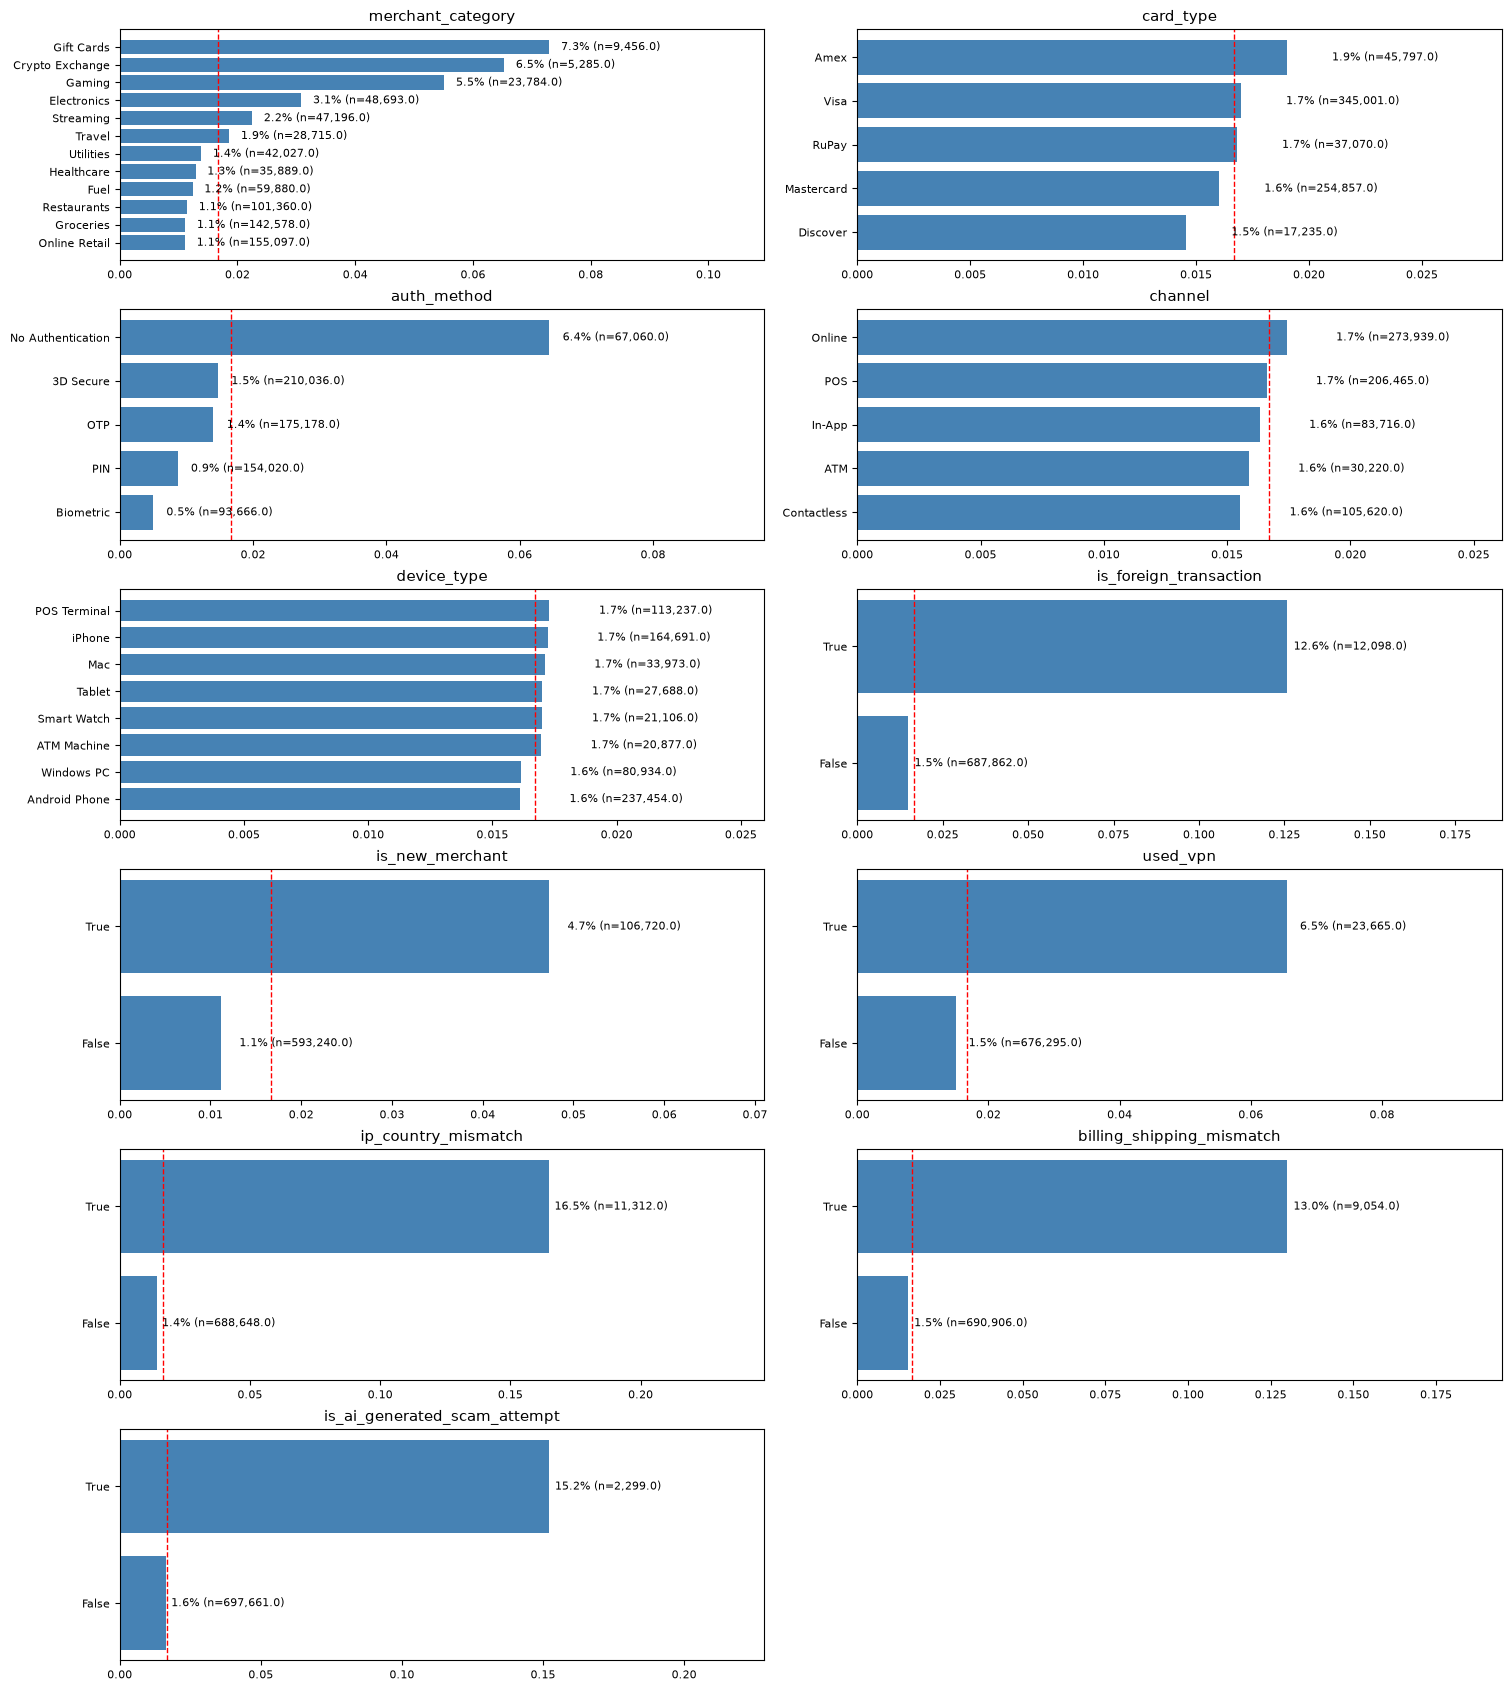

In [33]:
cat_features = [
    "merchant_category",
    "card_type",
    "auth_method",
    "channel",
    "device_type",
    "is_foreign_transaction",
    "is_new_merchant",
    "used_vpn",
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt"
]

plot_fraud_rates(train_df, cat_features)

## Findings

- `device_type`, `channel`, and `card_type` show relatively small differences in fraud rates across categories.

- Fraud rates vary more across different authentication methods.

- Binary indicators may also carry useful predictive signals.

## Hypotheses

- Test whether adding a binary `no_authentication` feature improves model performance while retaining the original `auth_method`.

- Evaluate whether removing weak categorical features affects cross-validation `ROC-AUC`.

- Investigate whether categorical features become more informative through interactions.

## Categorical Interactions

We can combine some features that do not show big difference in fraud rates in order to see whether they produce interaction patterns. Pairs we will examine:

- `device_type × channel`

- `device_type × card_type`

- `channel × card_type`

In [34]:
def plot_fraud_interaction(
    df,
    feature1,
    feature2,
    target="is_fraud"
):
    fraud_rate = df.pivot_table(
        index=feature1,
        columns=feature2,
        values=target,
        aggfunc="mean"
    )

    counts = df.pivot_table(
        index=feature1,
        columns=feature2,
        values=target,
        aggfunc="count"
    )

    annotations = fraud_rate.map(
        lambda x: f"{x:.1%}" if pd.notna(x) else "—"
    )

    plt.figure(figsize=(11, 6))

    sns.heatmap(
        fraud_rate,
        annot=annotations,
        fmt="",
        cmap="YlOrRd",
        linewidths=0.5,
        mask=counts.lt(100) | counts.isna(),
        cbar_kws={"label": "Fraud Rate"}
    )

    plt.title(f"Fraud Rate: {feature1} × {feature2}")
    plt.tight_layout()
    plt.show()

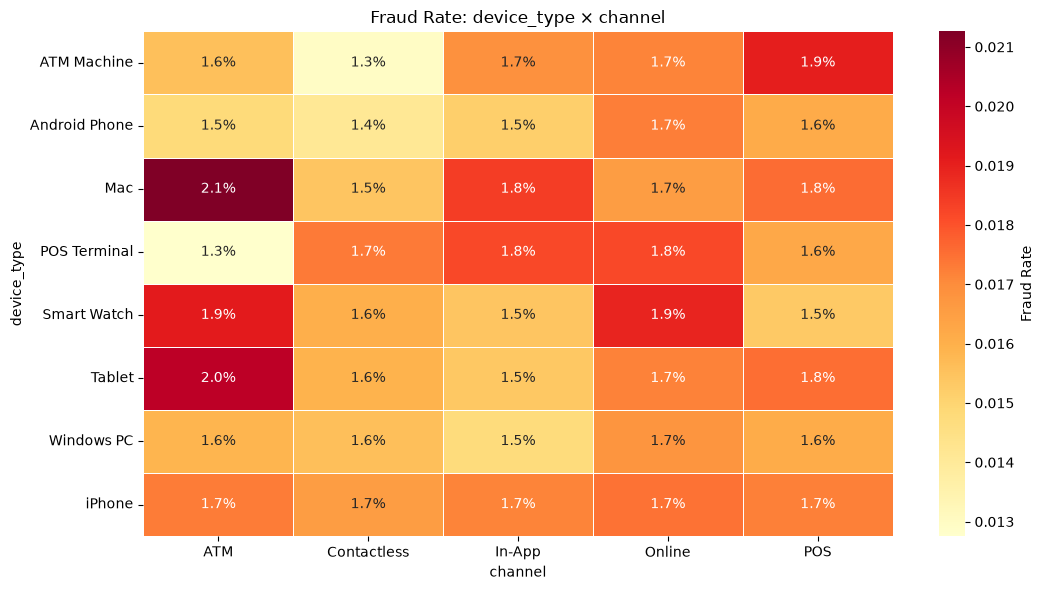

In [35]:
plot_fraud_interaction(
    train_df,
    "device_type",
    "channel"
)

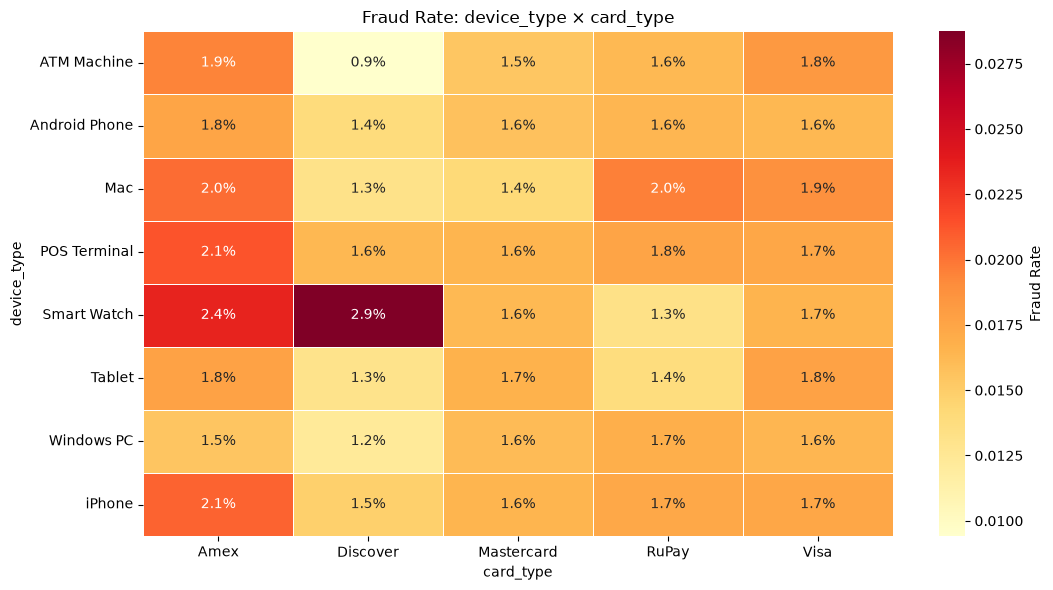

In [36]:
plot_fraud_interaction(
    train_df,
    "device_type",
    "card_type"
)

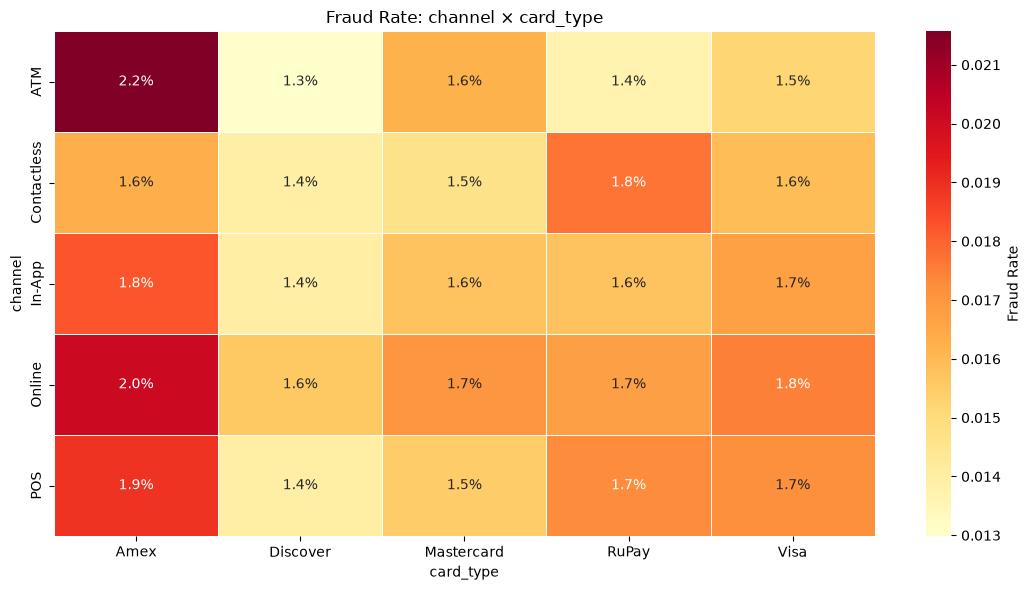

In [37]:
plot_fraud_interaction(
    train_df,
    "channel",
    "card_type"
)

## Findings

The heatmaps do not reveal strong or consistent interaction patterns. Most fraud rates remain relatively similar across combinations.

*Conclusion*: There is currently limited visual evidence that these interactions would improve predictive performance. We will retain the original features for the baseline and evaluate their contributions through ablation experiments.

## 3. Numerical Feature Interactions

We investigate whether combinations of numerical features reveal patterns that are not apparent when examining each feature individually. Pairs used:

- `merchant_risk_score × velocity_score`

- `txn_count_last_24h × hours_since_last_txn`

- `amount_usd × account_balance_usd`

To visualize these relationships, we divide each feature into five quantile-based bins and calculate the fraud rate for each combination.

In [39]:
def plot_numeric_interaction(
    df,
    feature1,
    feature2,
    target="is_fraud",
    n_bins=5
):
    # Split numeric features into quantile-based bins
    bins1 = pd.qcut(df[feature1], q=n_bins, duplicates="drop")
    bins2 = pd.qcut(df[feature2], q=n_bins, duplicates="drop")

    # Calculate fraud rate for each combination
    fraud_rate = pd.DataFrame({
        feature1: bins1,
        feature2: bins2,
        target: df[target]
    }).pivot_table(
        index=feature1,
        columns=feature2,
        values=target,
        aggfunc="mean",
        observed=True
    )

    # Plot heatmap
    plt.figure(figsize=(10, 6))

    sns.heatmap(
        fraud_rate,
        annot=True,
        fmt=".2%",
        cmap="YlOrRd",
        vmin=0
    )

    plt.title(f"Fraud Rate: {feature1} × {feature2}")
    plt.xlabel(feature2)
    plt.ylabel(feature1)
    plt.tight_layout()
    plt.show()

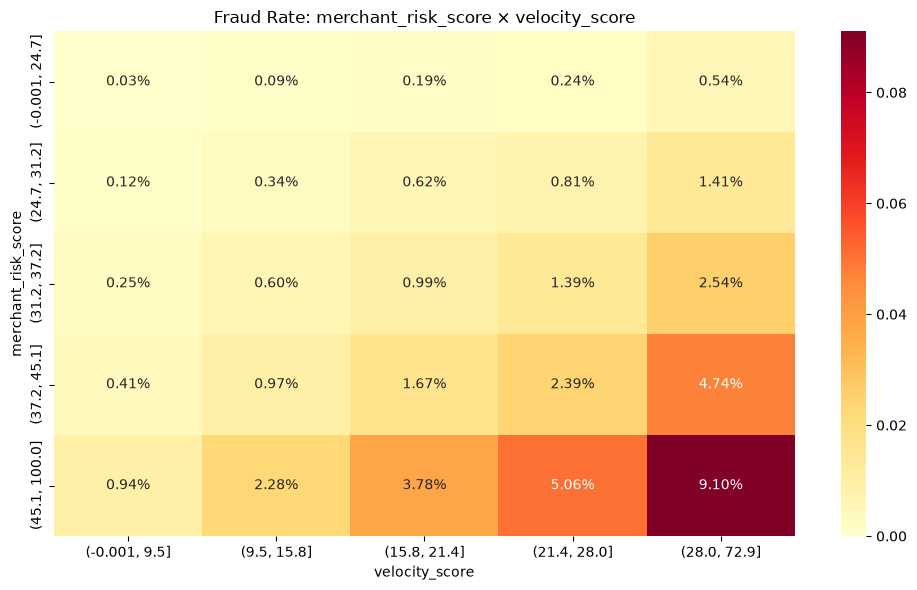

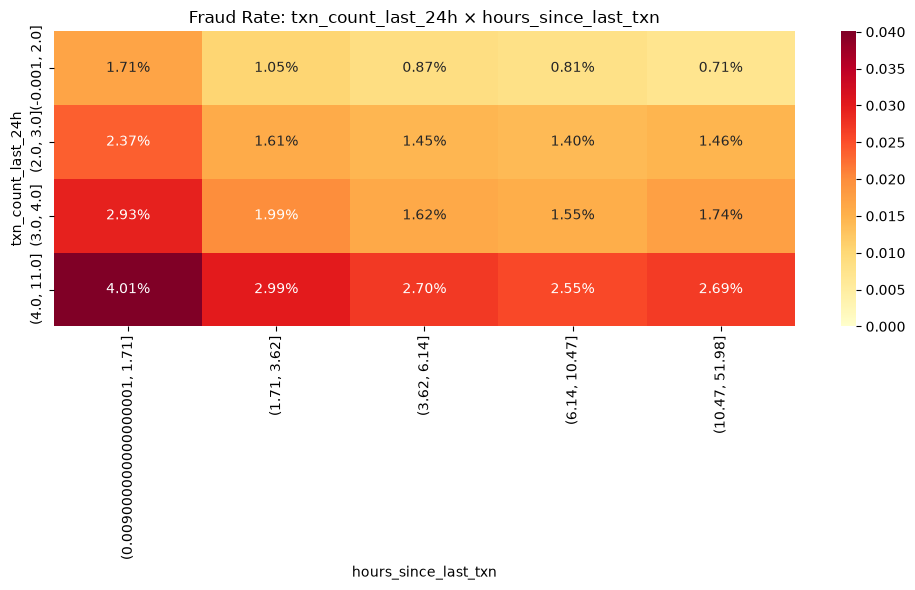

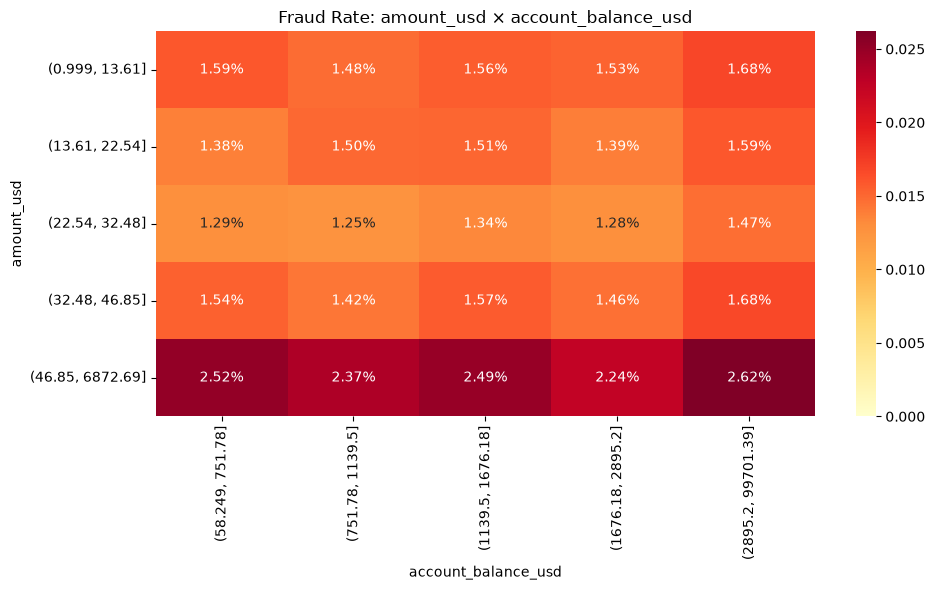

In [41]:
# Merchant risk × Transaction velocity
plot_numeric_interaction(
    train_df,
    "merchant_risk_score",
    "velocity_score"
)

# Transaction frequency × Time since last transaction
plot_numeric_interaction(
    train_df,
    "txn_count_last_24h",
    "hours_since_last_txn"
)

# Transaction amount × Account balance
plot_numeric_interaction(
    train_df,
    "amount_usd",
    "account_balance_usd"
)

## 3.1. Merchant Risk × Transaction Velocity

Fraud rates increase substantially as both `merchant_risk_score` and `velocity_score` increase.

The highest-risk combination reaches approximately ***9.1% fraud***, while combinations with lower feature values generally exhibit lower fraud rates.

*Hypothesis*: A multiplicative interaction between merchant risk and transaction velocity may provide additional predictive information.

Proposed feature: `risk_velocity` = `merchant_risk_score` * `velocity_score`

## 3.2. Transaction Count × Time Since Last Transaction

Higher transaction counts combined with shorter intervals between transactions are associated with increased fraud rates.

This pattern is consistent with the hypothesis that unusually frequent transaction activity may indicate fraud.

*Hypothesis*: A transaction frequency feature may capture this relationship.

Proposed feature: `txn_frequency` = `txn_count_last_24h` / (`hours_since_last_txn` + 1)

We should also examine the correlation between the original features to determine whether they contain overlapping information.

## 3.3. Transaction Amount × Account Balance

Fraud rates appear to vary primarily with `amount_usd`, while `account_balance_usd` shows relatively little additional variation across the examined bins.

To investigate if `amount_usd` rlative to `account_balance_usd` is more informative, we want to introduce `amount_to_balance_ration` = `amount_usd` / (`account_balance_usd` + 1)

In [49]:
train_df["amount_to_balance_ratio"] = (
    train_df["amount_usd"] /
    (train_df["account_balance_usd"] + 1)
)

auc = roc_auc_score(
    train_df["is_fraud"],
    train_df["amount_to_balance_ratio"]
)

print(f"ROC-AUC: {auc:.4f}")
print(f"Direction-independent AUC: {max(auc, 1 - auc):.4f}")

ROC-AUC: 0.5344
Direction-independent AUC: 0.5344


Our new feature performs slightly worse than transaction size. We can conclude that `amount_to_balance_ratio` does not provide stronger individual ranking.

# 4. Summary and Next Steps

Our exploratory analysis has identified several promising directions for feature engineering, as well as features with limited individual predictive strength.

The next step is to establish a reproducible `CatBoost` baseline using the original features.

Once the baseline is established, we will evaluate the following hypotheses:

- *Feature interactions*: Test `risk_velocity` and `txn_frequency`.

- *Ratio features*: Test whether `amount_to_balance_ratio` adds predictive value.

- *Categorical engineering*: Evaluate `no_authentication`.

- *Feature ablation*: Measure the effect of removing `account_balance_usd`, `device_type`, and other potentially weak features.

All experiments will use the same cross-validation splits and ROC-AUC metric to ensure fair comparisons.

The goal is to determine which hypotheses improve predictive performance rather than relying solely on patterns observed during EDA.